# ЛР3 по математической статистике
*Состав команды: Амосов Алексей M3338 (464991, Костаков Александр M3338 (466331)*

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## Задание 1

$((464991+466311) \% 3)+1 = 1$

## Вариант 1 

Предъявите доверительный интервал уровня $1-\alpha$ для указанного параметра при данных предположениях (с математическими обоснованиями). Проведите эксперимент по построению доверительных интервалов в зависимости от объёмов выборки: задайте массив объёмов выборок, для каждого объёма выборки сгенерируйте соответствующее количество выборок, для каждой посчитайте доверительный интервал, обработайте результаты (например, посчитайте долю «хороших» интервалов для каждого объёма выборки, проанализируйте границы и т.п.). Как изменился результат? Как объяснить?

Даны две независимые выборки $X = (X_1, \dots, X_n)$ и $Y = (Y_1, \dots, Y_m)$ из нормальных распределений $\mathcal{N}(\mu_1, \sigma_1^2)$ и $\mathcal{N}(\mu_2, \sigma_2^2)$ соответственно.

Оцениваемый параметр: $\tau = \mu_1 - \mu_2$. Дисперсии $\sigma_1^2$, $\sigma_2^2$ известны.

Параметры эксперимента: $\mu_1 = 2$, $\mu_2 = 1$, $\sigma_1^2 = 1$, $\sigma_2^2 = 0.5$.

Подсказка: воспользуйтесь функцией
$$
\frac{\overline{X} - \overline{Y} - \tau}{\sigma}, \qquad \sigma^2 = \frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}.
$$


### Теоретическое решение

$X_1, \dots, X_n \overset{\text{iid}}{\sim} \mathcal{N}(\mu_1, \sigma_1^2) \Rightarrow \overline{X} \sim \mathcal{N}(\mu_1, \sigma_1^2 / n)$, аналогично $\overline{Y} \sim \mathcal{N}(\mu_2, \sigma_2^2 / m)$.

$X$ и $Y$ независимы по условию $\Rightarrow$ $\overline{X}$ и $\overline{Y}$ независимы $\Rightarrow$

$$
\overline{X} - \overline{Y} \sim \mathcal{N}\left(\mu_1 - \mu_2, \frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}\right) = \mathcal{N}(\tau, \sigma^2).
$$

Тогда

$$
T(\tau, X, Y) = \frac{\overline{X} - \overline{Y} - \tau}{\sigma} \sim \mathcal{N}(0, 1),
$$

причём распределение $T$ не зависит от $\tau$.

Распишем через квантили стандартной гауссовской величины:

$$
P(q_{\alpha/2} < T(\tau, X, Y) < q_{1-\alpha/2}) = 1 - \alpha.
$$

$$
q_{\alpha/2} < \frac{\overline{X} - \overline{Y} - \tau}{\sigma} < q_{1-\alpha/2}
\iff
\overline{X} - \overline{Y} - q_{1-\alpha/2} \sigma < \tau < \overline{X} - \overline{Y} - q_{\alpha/2} \sigma.
$$

Так как $q_{\alpha/2} = -q_{1-\alpha/2}$, итого доверительный интервал уровня $1 - \alpha$:

$$
(\overline{X} - \overline{Y} - q_{1-\alpha/2} \sigma, \overline{X} - \overline{Y} + q_{1-\alpha/2} \sigma),
\qquad \sigma = \sqrt{\frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}}.
$$

### Эксперимент

Для каждого объёма выборки $n = m \in \{2^0, 2^1, \dots, 2^{10}\}$ генерируем $K = 16384$ пар независимых выборок $X \sim \mathcal{N}(2, 1)$, $Y \sim \mathcal{N}(1, 0.5)$ и на каждой паре строим доверительный интервал $(L, R)$ уровня $1 - \alpha = 0.95$ по полученной выше формуле.

Интервал считаем "хорошим", если он накрывает истинное значение $\tau = 1$, т.е. $L < \tau < R$, долей хороших интервалов будет эмпирическая оценка $P(L < \tau < R)$. Сама доля случайна со стандартным отклонением $\sqrt{\alpha(1 - \alpha)/K} \approx 0.0017$ (из дисперсии биномиального распределения и ЦПТ), поэтому отклонения от $1 - \alpha$ в пределах $\pm q_{1-\alpha/2} \sqrt{\alpha(1 - \alpha)/K} \approx \pm 0.0033$ ожидаемы 

Для каждого $n$ смотрим:
- долю хороших интервалов
- распределение границ $L$ и $R$, среднее, стандартное отклонение, 5%- и 95%-квантили
- ширину интервала $R - L$ в сравнении с теоретической $2 q_{1-\alpha/2} \sigma$.

Также для наглядности изображаем первые 100 интервалов при $n = m = 4$ и $n = m = 256$ в одном масштабе.

In [2]:
mu1, mu2 = 2, 1
var1, var2 = 1, 0.5
tau = mu1 - mu2
alpha = 0.05
sample_sizes = [2**p for p in range(11)]
n_samples = 16384
seed = 67

q = stats.norm.ppf(1 - alpha / 2)

def simulate_means(mu: float, var: float, size: int, count: int, rng: np.random.Generator,
                   batch_elements: int = 2**23) -> np.ndarray:
    means = np.empty(count)
    batch = max(1, batch_elements // size)
    for start in range(0, count, batch):
        stop = min(start + batch, count)
        samples = rng.normal(mu, math.sqrt(var), size=(stop - start, size))
        means[start:stop] = samples.mean(axis=1)
    return means

def confidence_interval(x_mean: np.ndarray, y_mean: np.ndarray, n: int, m: int) -> tuple[np.ndarray, np.ndarray]:
    sigma = math.sqrt(var1 / n + var2 / m)
    diff = x_mean - y_mean
    return diff - q * sigma, diff + q * sigma

rng = np.random.default_rng(seed)
lows = np.empty((len(sample_sizes), n_samples))
highs = np.empty((len(sample_sizes), n_samples))
for i, size in enumerate(sample_sizes):
    n = m = size
    x_mean = simulate_means(mu1, var1, n, n_samples, rng)
    y_mean = simulate_means(mu2, var2, m, n_samples, rng)
    lows[i], highs[i] = confidence_interval(x_mean, y_mean, n, m)

covered = (lows < tau) & (tau < highs)
coverage = covered.mean(axis=1)
coverage_std = math.sqrt(alpha * (1 - alpha) / n_samples)

print(f"1 - alpha = {1 - alpha}, ожидаемый разброс доли: ±{q * coverage_std:.4f} (уровень {1 - alpha})")
print(f"{'n = m':>6}{'доля хороших':>14}{'ширина':>10}{'E L':>10}{'E R':>10}{'sd L':>10}{'sd R':>10}")
for i, size in enumerate(sample_sizes):
    print(f"{size:>6}{coverage[i]:>14.4f}{(highs[i] - lows[i]).mean():>10.4f}"
          f"{lows[i].mean():>10.4f}{highs[i].mean():>10.4f}{lows[i].std():>10.4f}{highs[i].std():>10.4f}")

1 - alpha = 0.95, ожидаемый разброс доли: ±0.0033 (уровень 0.95)
 n = m  доля хороших    ширина       E L       E R      sd L      sd R
     1        0.9481    4.8009   -1.3975    3.4034    1.2301    1.2301
     2        0.9507    3.3948   -0.6948    2.6999    0.8626    0.8626
     4        0.9498    2.4005   -0.2000    2.2005    0.6148    0.6148
     8        0.9505    1.6974    0.1535    1.8509    0.4348    0.4348
    16        0.9509    1.2002    0.3961    1.5964    0.3063    0.3063
    32        0.9534    0.8487    0.5734    1.4221    0.2148    0.2148
    64        0.9493    0.6001    0.7003    1.3004    0.1538    0.1538
   128        0.9514    0.4243    0.7877    1.2121    0.1086    0.1086
   256        0.9493    0.3001    0.8502    1.1502    0.0768    0.0768
   512        0.9473    0.2122    0.8937    1.1058    0.0546    0.0546
  1024        0.9496    0.1500    0.9248    1.0749    0.0382    0.0382


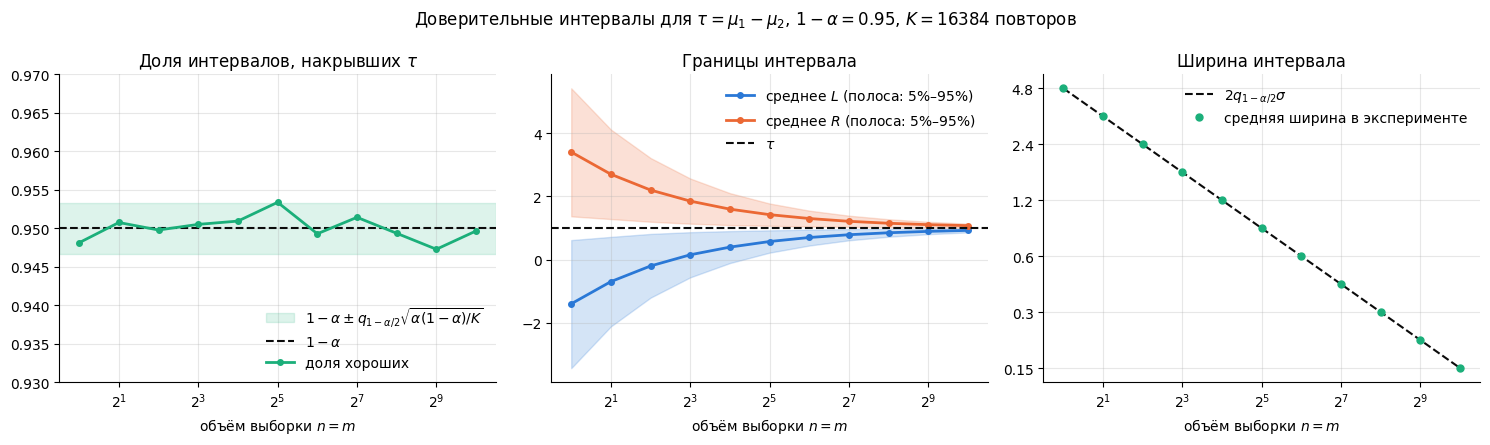

In [3]:
colors = {"low": "#2a78d6", "high": "#eb6834", "coverage": "#1baf7a", "truth": "#0b0b0b"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ax = axes[0]
ax.axhspan(1 - alpha - q * coverage_std, 1 - alpha + q * coverage_std, color=colors["coverage"], alpha=0.15,
           label=r"$1 - \alpha \pm q_{1-\alpha/2} \sqrt{\alpha(1-\alpha)/K}$")
ax.axhline(1 - alpha, color=colors["truth"], linestyle="--", linewidth=1.5, label=r"$1 - \alpha$")
ax.plot(sample_sizes, coverage, color=colors["coverage"], linewidth=2, marker="o", markersize=4, label="доля хороших")
ax.set_xscale("log", base=2)
ax.set_ylim(1 - alpha - 0.02, 1 - alpha + 0.02)
ax.set_xlabel("объём выборки $n = m$")
ax.set_title(r"Доля интервалов, накрывших $\tau$")
ax.legend(frameon=False, loc="lower right")

ax = axes[1]
for name, bound, label in (("low", lows, "$L$"), ("high", highs, "$R$")):
    ax.fill_between(sample_sizes, np.quantile(bound, 0.05, axis=1), np.quantile(bound, 0.95, axis=1),
                    color=colors[name], alpha=0.2)
    ax.plot(sample_sizes, bound.mean(axis=1), color=colors[name], linewidth=2, marker="o", markersize=4,
            label=f"среднее {label} (полоса: 5%–95%)")
ax.axhline(tau, color=colors["truth"], linestyle="--", linewidth=1.5, label=r"$\tau$")
ax.set_xscale("log", base=2)
ax.set_xlabel("объём выборки $n = m$")
ax.set_title("Границы интервала")
ax.legend(frameon=False)

ax = axes[2]
sizes = np.array(sample_sizes)
ax.plot(sizes, 2 * q * np.sqrt(var1 / sizes + var2 / sizes), color=colors["truth"], linestyle="--", linewidth=1.5,
        label=r"$2 q_{1-\alpha/2} \sigma$")
ax.plot(sample_sizes, (highs - lows).mean(axis=1), color=colors["coverage"], linewidth=0, marker="o", markersize=5,
        label="средняя ширина в эксперименте")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_yticks([0.15, 0.3, 0.6, 1.2, 2.4, 4.8], labels=["0.15", "0.3", "0.6", "1.2", "2.4", "4.8"])
ax.minorticks_off()
ax.set_xlabel("объём выборки $n = m$")
ax.set_title("Ширина интервала")
ax.legend(frameon=False)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(rf"Доверительные интервалы для $\tau = \mu_1 - \mu_2$, $1 - \alpha = {1 - alpha}$, $K = {n_samples}$ повторов")
fig.tight_layout()
plt.show()

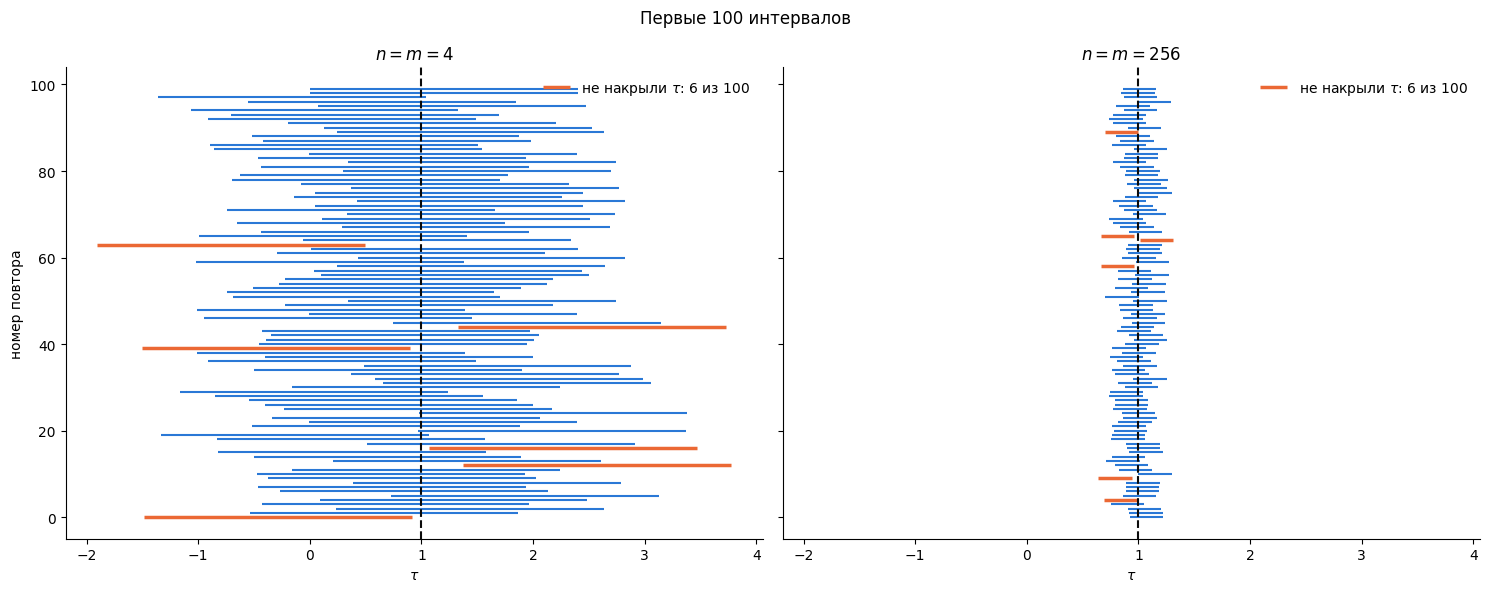

In [4]:
shown_sizes = [4, 256]
n_shown = 100

fig, axes = plt.subplots(1, len(shown_sizes), figsize=(15, 6), sharex=True, sharey=True)
for ax, size in zip(axes, shown_sizes):
    i = sample_sizes.index(size)
    good = covered[i, :n_shown]
    ys = np.arange(n_shown)
    ax.hlines(ys[good], lows[i, :n_shown][good], highs[i, :n_shown][good], color=colors["low"], linewidth=1.5)
    ax.hlines(ys[~good], lows[i, :n_shown][~good], highs[i, :n_shown][~good], color=colors["high"], linewidth=2.5,
              label=rf"не накрыли $\tau$: {(~good).sum()} из {n_shown}")
    ax.axvline(tau, color=colors["truth"], linestyle="--", linewidth=1.5)
    ax.set_title(f"$n = m = {size}$")
    ax.set_xlabel(r"$\tau$")
    ax.legend(frameon=False, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("номер повтора")
fig.suptitle(f"Первые {n_shown} интервалов")
fig.tight_layout()
plt.show()